In [1]:
# =====================================================================
#  N-CMAPSS RUL 파이프라인 — 피드백 반영 + 버그 보완 버전
# =====================================================================
#  [피드백 → 반영 위치 매핑]
#   F1) LCC 30→15 = 데이터 누수/평가방식 차이  → 누수 제거(F5)로 원인 차단 +
#                                              lcc_cv()에서 동일 프로토콜·가중치 스윕으로 재검증
#   F2) 단거리 분산은 모델 결함 아님(엔진 2~3개) → cross_val()이 mean±std·엔진수 반환/출력
#   F3) GPU 사용 + 샘플제한 해제                → DEVICE/.to(DEVICE), MAX_SAMPLES=None
#   F4) MLP는 sample_weight 무시               → 가중 학습에서 MLP 제외(GBM+RF)
#   F5) 스케일러/특징선택을 전체로 fit → 누수    → preprocess에서 스케일 제거,
#                                              CV/LCC 루프 '내부'에서 train에만 fit
#
#  [원본 대비 추가 버그 수정]
#   B1) BatchNorm + 마지막 batch=1 크래시        → DataLoader(drop_last=...) 가드
#   B2) forward()의 .squeeze() 0-d 붕괴          → .squeeze(-1)
#   B3) 재현성 없음(torch 시드 X)                → seed_everything()
#   B4) predict 시 전체 텐서 GPU 적재(OOM 위험)  → 배치 추론
#   B5) 메모리                                   → 윈도우 float32 캐스팅
# =====================================================================

In [2]:
# [F3] GPU 확인 + 재현성 시드
import torch, random
import numpy as np

print("PyTorch:", torch.__version__)
print("CUDA 사용 가능:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("[주의] GPU 미감지! '런타임 > 런타임 유형 변경 > GPU'로 바꾸세요.")
    print("    (torch 빌드가 '+cpu'면 GPU 런타임이어도 CPU로 돕니다)")

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(42)
print("연산 디바이스:", DEVICE)

PyTorch: 2.11.0+cu128
CUDA 사용 가능: True
GPU: Tesla T4
연산 디바이스: cuda


In [3]:
import torch
print("CUDA 사용 가능:", torch.cuda.is_available())   # True 여야 함
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "없음")

CUDA 사용 가능: True
GPU: Tesla T4


In [4]:
import os, warnings, pickle, joblib
import h5py
import matplotlib.pyplot as plt
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
warnings.filterwarnings('ignore')
print("[OK] 라이브러리 로드 완료")

[OK] 라이브러리 로드 완료


In [5]:
try:
    import matplotlib.font_manager as fm
    os.system('apt-get -qq install -y fonts-nanum > /dev/null 2>&1')
    fp = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
        plt.rcParams['font.family'] = 'NanumGothic'
    plt.rcParams['axes.unicode_minus'] = False
    print("[OK] 한글 폰트 설정 완료")
except Exception as e:
    print("폰트 설정 건너뜀:", e)

[OK] 한글 폰트 설정 완료


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
FOLDER   = '/content/drive/MyDrive/제주항공'
SAVE_DIR = f'{FOLDER}/최종베이스라인_수정'
os.makedirs(SAVE_DIR, exist_ok=True)

FILES = [
    f'{FOLDER}/N-CMAPSS_DS01-005.h5',
    f'{FOLDER}/N-CMAPSS_DS02-006.h5',
    f'{FOLDER}/N-CMAPSS_DS03-012.h5',
]
print("저장 위치:", SAVE_DIR)
for fp in FILES:
    print(("  [OK] " if os.path.exists(fp) else "  [X] 없음 ") + os.path.basename(fp))

저장 위치: /content/drive/MyDrive/제주항공/최종베이스라인_수정
  [OK] N-CMAPSS_DS01-005.h5
  [OK] N-CMAPSS_DS02-006.h5
  [OK] N-CMAPSS_DS03-012.h5


## 500 시점 동안 RUL 변화량

```python
import numpy as np   # 혹시 몰라 다시
W, Xs, Y, units, fc = load_file(FILES[0])   # DS01 로드

u0 = np.unique(units)[0]
m  = (units == u0)
y0 = Y[m]
print(f"엔진 {u0}: 시점 {m.sum():,}개, RUL {y0.max():.0f} → {y0.min():.0f}")
print(f"  WINDOW=50, DOWNSAMPLE=10 이면 창문 하나가 원본 {50*10}시점을 덮음")
print(f"  → 그 500시점 동안 RUL은 약 {(y0.max()-y0.min())/m.sum()*500:.4f}만큼 변함")
```


**결과**
  
  읽는 중... 완료 (4,906,636개 시점)
엔진 1: 시점 433,325개, RUL 99 → 0
  WINDOW=50, DOWNSAMPLE=10 이면 창문 하나가 원본 500시점을 덮음
  → 그 500시점 동안 RUL은 약 0.1142만큼 변함

================================================================================

================================================================================


## WINDOW 빠른 비교 (실험 완료 — 재실행 안 함)

DS01 단거리, `DOWNSAMPLE=10`, 트리(앙상블)만으로 `WINDOW` 50·75·100을 비교한 코드와 결과.

```python
import time

WINDOW_LIST_TEST = [50, 75, 100]
DOWNSAMPLE = 10          # RUL 변화량 0.11 확인 → 10 고정
WIN_STRIDE = 1

# 데이터 로드 + 클래스 하나 선택 (DS01 단거리 = fc 1)
W, Xs, Y, units, fc = load_file(FILES[0])
TARGET_FC = 1
mask = (fc == TARGET_FC)

for w in WINDOW_LIST_TEST:
    WINDOW = w
    Xw, Yw, Uw = preprocess_sequence(W[mask], Xs[mask], Y[mask], units[mask])
    cv = cross_val(Xw, Yw, Uw, 'ensemble')
    m, s, _ = cv['ensemble']
    print(f"WINDOW={w}: RMSE {m:.2f} ± {s:.2f} | 샘플 {len(Yw):,}")
```

**결과** — DS01-005 / 단거리 (엔진 2개)

| WINDOW | 샘플 수 | 앙상블 RMSE | 시간 |
|:------:|--------:|:-----------:|-----:|
| **50** | 84,651 | **13.76 ± 1.79** | 752초 |
| 75 | 84,601 | 14.10 ± 1.81 | 737초 |
| 100 | 84,551 | 14.15 ± 1.88 | 729초 |

→ WINDOW=50이 가장 낮음 → **50으로 확정** (75·100으로 키워도 나아지지 않음)

===============================================================================

In [8]:
WINDOW         = 50      # 실험 B 최적
MAX_RUL        = 125
SENSOR_STD_MIN = 0.01
FEATURE_RATIO  = 0.7
N_ESTIMATORS   = 150
# STEP           = 10      # 주의: 시점의 90%를 버림(여전히 부분표본)

# [F3] 샘플 수 제한 해제. RAM 부족으로 세션이 죽으면 None 대신 예: 60000
MAX_SAMPLES    = None

# [F1] 가중치 스윕(1=무가중 기준)으로 LCC 효과를 직접 확인
LCC_WEIGHT_LIST = (1, 3, 5, 10)
LCC_WEIGHT      = 5       # 최종 저장 모델에 쓸 값

CNN_LAYERS     = 3
CNN_EPOCHS     = 20
CNN_BATCH_SIZE = 256
CNN_LR         = 1e-3
RUN_CNN        = True     # CNN-LSTM 교차검증/저장 실행 여부(느리면 False)

DOWNSAMPLE = 10    # 원본 시계열 다운샘플(= 기존 STEP). 1이면 모든 시점 사용
WIN_STRIDE = 1    # 윈도우 간 간격. 키우면 겹침↓·샘플수↓ (메모리/속도 절약)

FC_LABELS = {1: '단거리', 2: '중거리', 3: '장거리'}
FC_COLORS = {1: '#E87A5D', 2: '#F5B942', 3: '#4C8EDA'}

print(f"WINDOW={WINDOW} | N_ESTIMATORS={N_ESTIMATORS} | MAX_SAMPLES={MAX_SAMPLES}")
print(f"LCC 가중치 스윕={LCC_WEIGHT_LIST} | CNN {CNN_LAYERS}층/{CNN_EPOCHS}ep | RUN_CNN={RUN_CNN}")

WINDOW=50 | N_ESTIMATORS=150 | MAX_SAMPLES=None
LCC 가중치 스윕=(1, 3, 5, 10) | CNN 3층/20ep | RUN_CNN=True


In [9]:
class CNNLSTM(nn.Module):
    """CNN 3층(단순→복합→추상 패턴) + 양방향 LSTM → RUL 1개."""
    def __init__(self, n_sensors, hidden=64):
        super().__init__()
        self.conv1 = nn.Conv1d(n_sensors, 32,  3, padding=1)
        self.conv2 = nn.Conv1d(32,        64,  3, padding=1)
        self.conv3 = nn.Conv1d(64,        128, 3, padding=1)
        self.bn1   = nn.BatchNorm1d(32)
        self.bn2   = nn.BatchNorm1d(64)
        self.bn3   = nn.BatchNorm1d(128)
        self.lstm  = nn.LSTM(128, hidden, 2, batch_first=True,
                             bidirectional=True, dropout=0.2)
        self.fc = nn.Sequential(
            nn.Linear(hidden * 2, 32), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(32, 1))

    def forward(self, x):
        x = x.transpose(1, 2)
        x = torch.relu(self.bn1(self.conv1(x)))
        x = torch.relu(self.bn2(self.conv2(x)))
        x = torch.relu(self.bn3(self.conv3(x)))
        x = x.transpose(1, 2)
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :]).squeeze(-1)   # [버그] squeeze()→squeeze(-1)


def train_cnnlstm(Xw_tr, Y_tr):
    torch.manual_seed(42)                            # [버그] 폴드별 재현성
    n_sensors = Xw_tr.shape[2]
    model     = CNNLSTM(n_sensors=n_sensors).to(DEVICE)   # [F3] 모델 GPU
    optimizer = torch.optim.Adam(model.parameters(), lr=CNN_LR)
    criterion = nn.MSELoss()

    ds = torch.utils.data.TensorDataset(
        torch.FloatTensor(Xw_tr), torch.FloatTensor(Y_tr))
    # [버그] BatchNorm은 마지막 batch=1이면 에러 → drop_last로 방지.
    #        단, 표본이 batch보다 작으면 빈 로더가 되므로 가드.
    drop_last = len(ds) > CNN_BATCH_SIZE
    dl = torch.utils.data.DataLoader(
        ds, batch_size=CNN_BATCH_SIZE, shuffle=True, drop_last=drop_last)

    model.train()
    for _ in range(CNN_EPOCHS):
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)    # [F3] 배치 GPU
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
    return model


def predict_cnnlstm(model, Xw, batch_size=512):
    # [버그] 전체를 한 번에 GPU에 올리지 않고 배치 추론(OOM 방지)
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(Xw), batch_size):
            xb = torch.FloatTensor(Xw[i:i+batch_size]).to(DEVICE)
            preds.append(model(xb).cpu().numpy().reshape(-1))
    return np.concatenate(preds) if preds else np.array([])

print("[OK] CNN-LSTM 정의 완료")

[OK] CNN-LSTM 정의 완료


In [10]:
def load_file(filepath):
    print("  읽는 중...", end=" ")
    with h5py.File(filepath, 'r') as f:
        W  = f['W_dev'][:]
        Xs = f['X_s_dev'][:]
        Y  = f['Y_dev'][:].flatten()
        A  = f['A_dev'][:]
    units = A[:, 0].astype(int)
    fc    = A[:, 2].astype(int)
    print(f"완료 ({len(Y):,}개 시점)")
    return W, Xs, Y, units, fc


# 셀 8의 preprocess_sequence 교체
def preprocess_sequence(W, Xs, Y, units):
    X_raw  = np.concatenate([W, Xs], axis=1)
    valid  = X_raw.std(axis=0) > SENSOR_STD_MIN
    X_raw  = X_raw[:, valid]
    Y_clip = np.clip(Y, 0, MAX_RUL)

    Xw, Yw, Uw = [], [], []
    for u in np.unique(units):
        mask = (units == u)
        Xu   = X_raw[mask][::DOWNSAMPLE]          # ← STEP → DOWNSAMPLE
        Yu   = Y_clip[mask][::DOWNSAMPLE]
        if len(Xu) <= WINDOW:
            continue
        for i in range(0, len(Xu) - WINDOW, WIN_STRIDE):   # ← stride 적용
            Xw.append(Xu[i:i+WINDOW])
            Yw.append(Yu[i+WINDOW])
            Uw.append(u)

    if len(Yw) == 0:
        return None, None, None

    Xw = np.asarray(Xw, dtype=np.float32)
    Yw = np.asarray(Yw, dtype=np.float32)
    Uw = np.asarray(Uw)

    if MAX_SAMPLES and len(Yw) > MAX_SAMPLES:
        idx = np.random.RandomState(42).choice(len(Yw), MAX_SAMPLES, replace=False)
        idx.sort()
        Xw, Yw, Uw = Xw[idx], Yw[idx], Uw[idx]
    return Xw, Yw, Uw


def extract_features(Xw_scaled):
    """스케일 완료 윈도우 → 트리 모델용 통계 특징."""
    return np.concatenate([
        Xw_scaled.mean(axis=1), Xw_scaled.std(axis=1),
        Xw_scaled.max(axis=1),  Xw_scaled.min(axis=1),
        Xw_scaled[:, -1, :] - Xw_scaled[:, 0, :],
        np.diff(Xw_scaled, axis=1).mean(axis=1),
    ], axis=1)


def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

print("[OK] 공통 함수 정의 완료")

[OK] 공통 함수 정의 완료


In [11]:
# 교차검증 (Leave-One-Engine-Out)
# [F5] 스케일·특징선택을 폴드 '내부' train에만 fit
# [F2] 평균 + 표준편차 + 엔진수 반환
# GBM/RF/MLP/앙상블을 한 번의 학습으로 모두 반환 (추가 비용 없음)
def _agg(folds):
    if not folds:
        return None
    return (float(np.mean(folds)), float(np.std(folds)), folds)

def cross_val(Xw_raw, Y, units, model_type='ensemble'):
    all_units = np.unique(units)
    if len(all_units) < 2:
        return None

    # ── CNN-LSTM ─────────────────────────────────────────────
    if model_type == 'cnnlstm':
        folds = []
        for test_unit in all_units:
            tr = (units != test_unit); te = (units == test_unit)
            if tr.sum() == 0 or te.sum() == 0:
                continue
            ns = Xw_raw[tr].shape[2]
            scaler = MinMaxScaler()
            Xtr = scaler.fit_transform(Xw_raw[tr].reshape(-1, ns)).reshape(Xw_raw[tr].shape)
            Xte = scaler.transform(Xw_raw[te].reshape(-1, ns)).reshape(Xw_raw[te].shape)
            model = train_cnnlstm(Xtr, Y[tr])
            folds.append(rmse(Y[te], predict_cnnlstm(model, Xte)))
        return {'cnnlstm': _agg(folds), 'n_engines': len(all_units)}

    # ── 트리 모델: GBM/RF/MLP/앙상블 동시 ────────────────────
    fr = {'gbm': [], 'rf': [], 'mlp': [], 'ensemble': []}
    for test_unit in all_units:
        tr = (units != test_unit); te = (units == test_unit)
        if tr.sum() == 0 or te.sum() == 0:
            continue
        Xw_tr, Y_tr = Xw_raw[tr], Y[tr]
        Xw_te, Y_te = Xw_raw[te], Y[te]
        ns = Xw_tr.shape[2]

        scaler = MinMaxScaler()                       # [F5] train으로만 fit
        Xtr = scaler.fit_transform(Xw_tr.reshape(-1, ns)).reshape(Xw_tr.shape)
        Xte = scaler.transform(Xw_te.reshape(-1, ns)).reshape(Xw_te.shape)
        Ftr = extract_features(Xtr)
        Fte = extract_features(Xte)
        k   = max(1, int(Ftr.shape[1] * FEATURE_RATIO))
        sel = SelectKBest(f_regression, k=k)          # [F5] train으로만 fit
        Ftr = sel.fit_transform(Ftr, Y_tr)
        Fte = sel.transform(Fte)

        gbm = GradientBoostingRegressor(n_estimators=N_ESTIMATORS, max_depth=4, random_state=42)
        rf  = RandomForestRegressor(n_estimators=N_ESTIMATORS, max_depth=8, random_state=42, n_jobs=-1)
        mlp = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)
        gbm.fit(Ftr, Y_tr); rf.fit(Ftr, Y_tr); mlp.fit(Ftr, Y_tr)

        p_g = gbm.predict(Fte); p_r = rf.predict(Fte); p_m = mlp.predict(Fte)
        p_e = (p_g + p_r + p_m) / 3                   # 앙상블 = 세 모델 평균
        fr['gbm'].append(rmse(Y_te, p_g))
        fr['rf'].append(rmse(Y_te, p_r))
        fr['mlp'].append(rmse(Y_te, p_m))
        fr['ensemble'].append(rmse(Y_te, p_e))

    out = {name: _agg(folds) for name, folds in fr.items()}
    out['n_engines'] = len(all_units)
    return out

print("[OK] cross_val 정의 완료 (GBM/RF/MLP/앙상블 동시 출력)")

[OK] cross_val 정의 완료 (GBM/RF/MLP/앙상블 동시 출력)


In [12]:
# baseline과 '동일한' LOO-CV 위에서, 누수 없이, 가중치를 스윕(1=무가중).
# [F4] MLP는 sample_weight를 무시하므로 GBM+RF만 가중 학습.
def lcc_cv(Xw_raw, Y, units, weights=LCC_WEIGHT_LIST, few_ratio=0.2, seed=42):
    all_units = np.unique(units)
    if len(all_units) < 2:
        return {}
    rng = np.random.RandomState(seed)
    results = {}
    for w in weights:
        fold_rmses = []
        for te_unit in all_units:
            tr = (units != te_unit); te = (units == te_unit)
            if tr.sum() == 0 or te.sum() == 0:
                continue
            Xw_tr, Y_tr = Xw_raw[tr], Y[tr]
            Xw_te, Y_te = Xw_raw[te], Y[te]
            ns = Xw_tr.shape[2]

            scaler = MinMaxScaler()
            Xtr = scaler.fit_transform(Xw_tr.reshape(-1, ns)).reshape(Xw_tr.shape)
            Xte = scaler.transform(Xw_te.reshape(-1, ns)).reshape(Xw_te.shape)
            Ftr = extract_features(Xtr); Fte = extract_features(Xte)
            k   = max(1, int(Ftr.shape[1] * FEATURE_RATIO))
            sel = SelectKBest(f_regression, k=k)
            Ftr = sel.fit_transform(Ftr, Y_tr); Fte = sel.transform(Fte)

            n_few = max(1, int(len(Ftr) * few_ratio))
            few   = rng.choice(len(Ftr), n_few, replace=False)
            Fc = np.vstack([Ftr, Ftr[few]])
            Yc = np.concatenate([Y_tr, Y_tr[few]])
            wt = np.concatenate([np.ones(len(Ftr)), np.ones(n_few) * w])

            gbm = GradientBoostingRegressor(n_estimators=N_ESTIMATORS, max_depth=4, random_state=42)
            rf  = RandomForestRegressor(n_estimators=N_ESTIMATORS, max_depth=8, random_state=42, n_jobs=-1)
            gbm.fit(Fc, Yc, sample_weight=wt)         # [F4] 가중 반영
            rf.fit(Fc, Yc, sample_weight=wt)
            pred = (gbm.predict(Fte) + rf.predict(Fte)) / 2
            fold_rmses.append(rmse(Y_te, pred))
        if fold_rmses:
            results[w] = (float(np.mean(fold_rmses)), float(np.std(fold_rmses)), fold_rmses)
    return results

print("[OK] lcc_cv 정의 완료")

[OK] lcc_cv 정의 완료


In [13]:
# ═══════════════════════════════════════════════════════════════
# 순수 무가중 GBM+RF 앙상블 (복제 X · sample_weight X)
# w=0
# ═══════════════════════════════════════════════════════════════
def gbm_rf_cv(Xw_raw, Y, units):
    all_units = np.unique(units)
    if len(all_units) < 2:
        return None
    folds = []
    for test_unit in all_units:
        tr = (units != test_unit); te = (units == test_unit)   # 엔진 단위 분리(누수 차단)
        if tr.sum() == 0 or te.sum() == 0:
            continue
        Xw_tr, Y_tr = Xw_raw[tr], Y[tr]
        Xw_te, Y_te = Xw_raw[te], Y[te]
        ns = Xw_tr.shape[2]

        sc = MinMaxScaler()                                    # [F5] 학습으로만 fit
        Xtr = sc.fit_transform(Xw_tr.reshape(-1, ns)).reshape(Xw_tr.shape)
        Xte = sc.transform(Xw_te.reshape(-1, ns)).reshape(Xw_te.shape)
        Ftr = extract_features(Xtr); Fte = extract_features(Xte)
        k = max(1, int(Ftr.shape[1] * FEATURE_RATIO))
        sel = SelectKBest(f_regression, k=k)                   # [F5] 학습으로만 fit
        Ftr = sel.fit_transform(Ftr, Y_tr); Fte = sel.transform(Fte)

        gbm = GradientBoostingRegressor(n_estimators=N_ESTIMATORS, max_depth=4, random_state=42)
        rf  = RandomForestRegressor(n_estimators=N_ESTIMATORS, max_depth=8, random_state=42, n_jobs=-1)
        gbm.fit(Ftr, Y_tr); rf.fit(Ftr, Y_tr)                  # sample_weight 없음 = 순수 무가중
        pred = (gbm.predict(Fte) + rf.predict(Fte)) / 2        # GBM+RF 2모델 평균
        folds.append(rmse(Y_te, pred))
    if not folds:
        return None
    return float(np.mean(folds)), float(np.std(folds)), folds

print("[OK] gbm_rf_cv 정의 완료 (순수 무가중 GBM+RF)")

[OK] gbm_rf_cv 정의 완료 (순수 무가중 GBM+RF)


##초기 실험 코드 & 결과
```python
#실험 시작

results = {}
MODELS = ['gbm', 'rf', 'mlp', 'ensemble']

for filepath in FILES:
    if not os.path.exists(filepath):
        print(f"\n[주의] {os.path.basename(filepath)} 없음, 건너뜀"); continue

    ds_key = os.path.basename(filepath).replace('N-CMAPSS_', '').replace('.h5', '')
    print(f"\n{'='*60}\n  {ds_key}\n{'='*60}")
    W, Xs, Y, units, fc = load_file(filepath)
    print(f"  비행 클래스: {[FC_LABELS.get(f, str(f)) for f in np.unique(fc)]}")

    for fc_type in np.unique(fc):
        mask  = (fc == fc_type)
        label = f"{ds_key} / {FC_LABELS.get(fc_type, str(fc_type))}"
        n_u   = len(np.unique(units[mask]))
        print(f"\n  ▶ {FC_LABELS.get(fc_type,'?')} | 엔진 {n_u}개", end="  ")
        if n_u < 2:
            print("→ [주의] 엔진 부족"); continue

        Xw, Yw, Uw = preprocess_sequence(W[mask], Xs[mask], Y[mask], units[mask])
        if Xw is None:
            print("→ [주의] 데이터 부족"); continue
        print(f"| 샘플 {len(Yw):,}개")

        # ── 트리 4종 (한 번에) ─────────────────────────────────
        print("    트리모델 학습 중...")
        cv = cross_val(Xw, Yw, Uw, 'ensemble')
        for name in MODELS:
            m, s, folds = cv[name]
            tag = "  ←앙상블" if name == 'ensemble' else ""
            print(f"      {name:9s} RMSE {m:6.2f} ± {s:4.2f}  폴드 {[round(f,1) for f in folds]}{tag}")
        if n_u < 3:
            print("      [주의] 엔진<3 → 분산 큼(해석 주의)")

        # ── CNN-LSTM ───────────────────────────────────────────
        cnn = None
        if RUN_CNN:
            print("    CNN-LSTM 학습 중...", end="  ")
            cnn = cross_val(Xw, Yw, Uw, 'cnnlstm')['cnnlstm']
            if cnn:
                m, s, folds = cnn
                print(f"→ RMSE {m:.2f} ± {s:.2f}  폴드 {[round(f,1) for f in folds]}")
            else:
                print("→ 실패")

        # ── LCC 가중치 스윕 (단거리만) ─────────────────────────
        lcc_sweep = {}
        if fc_type == 1:
            print("    LCC 가중치 스윕...", end="  ")
            res = lcc_cv(Xw, Yw, Uw, weights=LCC_WEIGHT_LIST)
            lcc_sweep = {w: v[0] for w, v in res.items()}
            print(" / ".join([f"w={w}:{m:.2f}" for w, m in lcc_sweep.items()]))

        results[label] = dict(cv=cv, cnn=cnn, lcc_sweep=lcc_sweep,
                              n_engines=n_u, fc=fc_type, ds=ds_key)

print("\n[OK] 실험 완료")

```


###실험 로그 — DS01 완료 / DS02 진행 중

```text
============================================================
  DS01-005
============================================================
  읽는 중... 완료 (4,906,636개 시점)
  비행 클래스: ['단거리', '중거리', '장거리']

  ▶ 단거리 | 엔진 2개  | 샘플 84,651개
    트리모델 학습 중...
      gbm       RMSE  16.88 ± 1.12  폴드 [18.0, 15.8]
      rf        RMSE  21.08 ± 0.26  폴드 [21.3, 20.8]
      mlp       RMSE  12.13 ± 1.20  폴드 [10.9, 13.3]
      ensemble  RMSE  13.76 ± 1.79  폴드 [15.5, 12.0]  ←앙상블
      [주의] 엔진<3 → 분산 큼(해석 주의)
    CNN-LSTM 학습 중...  → RMSE 10.35 ± 3.38  폴드 [7.0, 13.7]
    LCC 가중치 스윕...  w=1:18.29 / w=3:18.36 / w=5:18.43 / w=10:18.55

  ▶ 중거리 | 엔진 2개  | 샘플 172,891개
    트리모델 학습 중...
      gbm       RMSE  22.80 ± 2.26  폴드 [25.1, 20.5]
      rf        RMSE  26.41 ± 1.24  폴드 [27.6, 25.2]
      mlp       RMSE  15.23 ± 0.88  폴드 [14.4, 16.1]
      ensemble  RMSE  17.02 ± 4.37  폴드 [21.4, 12.7]  ←앙상블
      [주의] 엔진<3 → 분산 큼(해석 주의)
    CNN-LSTM 학습 중...  → RMSE 17.36 ± 4.94  폴드 [12.4, 22.3]

  ▶ 장거리 | 엔진 2개  | 샘플 232,824개
    트리모델 학습 중...
      gbm       RMSE  17.56 ± 1.23  폴드 [16.3, 18.8]
      rf        RMSE  21.17 ± 1.73  폴드 [19.4, 22.9]
      mlp       RMSE  13.44 ± 2.80  폴드 [16.2, 10.6]
      ensemble  RMSE  15.09 ± 1.39  폴드 [13.7, 16.5]  ←앙상블
      [주의] 엔진<3 → 분산 큼(해석 주의)
    CNN-LSTM 학습 중...  → RMSE 12.06 ± 0.60  폴드 [12.7, 11.5]

============================================================
  DS02-006
============================================================
  읽는 중... 완료 (5,263,447개 시점)
  비행 클래스: ['장거리']

  ▶ 장거리 | 엔진 6개  | 샘플 526,047개
    트리모델 학습 중...   (진행 중)
```



In [14]:
import pickle
results = {}
MODELS = ['gbm', 'rf', 'mlp', 'ensemble']

import joblib

def run_one_file(filepath):
    out = {}
    ds_key = os.path.basename(filepath).replace('N-CMAPSS_', '').replace('.h5', '')
    print(f"\n{'='*60}\n  {ds_key} (실험 시작)\n{'='*60}")
    W, Xs, Y, units, fc = load_file(filepath)
    for fc_type in np.unique(fc):
        mask  = (fc == fc_type)
        label = f"{ds_key} / {FC_LABELS.get(fc_type, str(fc_type))}"
        n_u   = len(np.unique(units[mask]))
        print(f"\n  ▶ {FC_LABELS.get(fc_type,'?')} | 엔진 {n_u}개", end="  ")
        if n_u < 2:
            print("→ [주의] 엔진 부족"); continue
        Xw, Yw, Uw = preprocess_sequence(W[mask], Xs[mask], Y[mask], units[mask])
        if Xw is None:
            print("→ [주의] 데이터 부족"); continue
        print(f"| 샘플 {len(Yw):,}개")

        # ── 교차검증 (성능 측정) ───────────────────────────────
        print("    트리모델 학습 중 (교차검증)...")
        cv = cross_val(Xw, Yw, Uw, 'ensemble')
        for name in MODELS:
            m, s, folds = cv[name]
            tag = "  ←앙상블" if name == 'ensemble' else ""
            print(f"      {name:9s} RMSE {m:6.2f} ± {s:4.2f}  폴드 {[round(f,1) for f in folds]}{tag}")

        cnn = None
        if RUN_CNN:
            print("    CNN-LSTM 학습 중 (교차검증)...", end="  ")
            cnn = cross_val(Xw, Yw, Uw, 'cnnlstm')['cnnlstm']
            if cnn:
                m, s, folds = cnn
                print(f"→ RMSE {m:.2f} ± {s:.2f}")

        lcc_sweep = {}
        if fc_type == 1:
            res = lcc_cv(Xw, Yw, Uw, weights=LCC_WEIGHT_LIST)
            lcc_sweep = {w: v[0] for w, v in res.items()}

        # ── 최종 배포 모델: 전체 데이터로 학습 + 저장 ────────
        print("    최종 모델 학습 + 저장 중...", end="  ")
        ns = Xw.shape[2]
        scaler = MinMaxScaler().fit(Xw.reshape(-1, ns))          # 전체로 fit (최종모델)
        Xw_s = scaler.transform(Xw.reshape(-1, ns)).reshape(Xw.shape)
        F = extract_features(Xw_s)
        k = max(1, int(F.shape[1] * FEATURE_RATIO))
        selector = SelectKBest(f_regression, k=k).fit(F, Yw)
        F_sel = selector.transform(F)
        gbm = GradientBoostingRegressor(n_estimators=N_ESTIMATORS, max_depth=4, random_state=42)
        rf  = RandomForestRegressor(n_estimators=N_ESTIMATORS, max_depth=8, random_state=42, n_jobs=-1)
        mlp = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)
        gbm.fit(F_sel, Yw); rf.fit(F_sel, Yw); mlp.fit(F_sel, Yw)
        bundle = dict(scaler=scaler, selector=selector, gbm=gbm, rf=rf, mlp=mlp, n_sensors=ns)

        safe = label.replace(' / ', '_').replace(' ', '')
        joblib.dump(bundle, f'{SAVE_DIR}/model_{safe}.pkl')      # 모델 저장

        if RUN_CNN:
            cnn_model = train_cnnlstm(Xw_s, Yw)
            torch.save({'state_dict': cnn_model.state_dict(), 'n_sensors': ns},
                       f'{SAVE_DIR}/cnn_{safe}.pt')
        print(f"→ model_{safe}.pkl 저장 완료")

        out[label] = dict(cv=cv, cnn=cnn, lcc_sweep=lcc_sweep,
                          n_engines=n_u, fc=fc_type, ds=ds_key)
    return out

def get_or_run(filepath):
    """저장 있으면 불러오고, 없으면 실험 후 저장. results에 병합."""
    ds_key = os.path.basename(filepath).replace('N-CMAPSS_', '').replace('.h5', '')
    path = f'{SAVE_DIR}/results_{ds_key}.pkl'
    if os.path.exists(path):
        with open(path, 'rb') as f:
            out = pickle.load(f)
        print(f"[OK] {ds_key}: 저장된 결과 불러옴 ({len(out)}개 케이스) — 실험 스킵")
    else:
        if not os.path.exists(filepath):
            print(f"[주의] {os.path.basename(filepath)} 파일 없음"); return
        out = run_one_file(filepath)
        with open(path, 'wb') as f:
            pickle.dump(out, f)
        print(f"\n[저장] {ds_key}: 실험 완료 + 저장됨 → results_{ds_key}.pkl")
    results.update(out)
    return out

print("[OK] 준비 완료. DS01/DS02/DS03 셀을 각각 돌리세요.")

[OK] 준비 완료. DS01/DS02/DS03 셀을 각각 돌리세요.


In [15]:
def get_or_run_class(filepath, fc_type):
    """DS 파일의 특정 비행클래스(1=단/2=중/3=장) 하나만 저장/재개."""
    ds_key = os.path.basename(filepath).replace('N-CMAPSS_', '').replace('.h5', '')
    cls    = FC_LABELS.get(fc_type, str(fc_type))
    label  = f"{ds_key} / {cls}"
    path   = f'{SAVE_DIR}/results_{ds_key}_{cls}.pkl'          # 클래스별 저장 파일
    if os.path.exists(path):
        with open(path, 'rb') as f:
            d = pickle.load(f)
        print(f"[OK] {label}: 저장된 결과 불러옴 — 실험 스킵")
        results[label] = d
        return d

    if not os.path.exists(filepath):
        print(f"[주의] {os.path.basename(filepath)} 파일 없음"); return
    W, Xs, Y, units, fc = load_file(filepath)
    mask = (fc == fc_type)
    n_u  = len(np.unique(units[mask]))
    print(f"\n{'='*60}\n  {label} | 엔진 {n_u}개\n{'='*60}")
    if n_u < 2:
        print("→ [주의] 엔진 부족, 건너뜀"); return
    Xw, Yw, Uw = preprocess_sequence(W[mask], Xs[mask], Y[mask], units[mask])
    if Xw is None:
        print("→ [주의] 데이터 부족"); return
    print(f"  샘플 {len(Yw):,}개")

    # ── 교차검증 ──
    print("    트리모델 학습 중 (교차검증)...")
    cv = cross_val(Xw, Yw, Uw, 'ensemble')
    for name in MODELS:
        m, s, folds = cv[name]
        tag = "  ←앙상블" if name == 'ensemble' else ""
        print(f"      {name:9s} RMSE {m:6.2f} ± {s:4.2f}  폴드 {[round(f,1) for f in folds]}{tag}")

    cnn = None
    if RUN_CNN:
        print("    CNN-LSTM 학습 중 (교차검증)...", end="  ")
        cnn = cross_val(Xw, Yw, Uw, 'cnnlstm')['cnnlstm']
        if cnn:
            m, s, folds = cnn
            print(f"→ RMSE {m:.2f} ± {s:.2f}")

    lcc_sweep = {}
    if fc_type == 1:
        res = lcc_cv(Xw, Yw, Uw, weights=LCC_WEIGHT_LIST)
        lcc_sweep = {w: v[0] for w, v in res.items()}

    # ── 최종 모델 저장 ──
    print("    최종 모델 학습 + 저장 중...", end="  ")
    ns = Xw.shape[2]
    scaler = MinMaxScaler().fit(Xw.reshape(-1, ns))
    Xw_s = scaler.transform(Xw.reshape(-1, ns)).reshape(Xw.shape)
    F = extract_features(Xw_s)
    k = max(1, int(F.shape[1] * FEATURE_RATIO))
    selector = SelectKBest(f_regression, k=k).fit(F, Yw)
    F_sel = selector.transform(F)
    gbm = GradientBoostingRegressor(n_estimators=N_ESTIMATORS, max_depth=4, random_state=42)
    rf  = RandomForestRegressor(n_estimators=N_ESTIMATORS, max_depth=8, random_state=42, n_jobs=-1)
    mlp = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)
    gbm.fit(F_sel, Yw); rf.fit(F_sel, Yw); mlp.fit(F_sel, Yw)
    bundle = dict(scaler=scaler, selector=selector, gbm=gbm, rf=rf, mlp=mlp, n_sensors=ns)
    safe = label.replace(' / ', '_').replace(' ', '')
    joblib.dump(bundle, f'{SAVE_DIR}/model_{safe}.pkl')
    if RUN_CNN:
        cnn_model = train_cnnlstm(Xw_s, Yw)
        torch.save({'state_dict': cnn_model.state_dict(), 'n_sensors': ns}, f'{SAVE_DIR}/cnn_{safe}.pt')
    print(f"→ model_{safe}.pkl 저장 완료")

    d = dict(cv=cv, cnn=cnn, lcc_sweep=lcc_sweep, n_engines=n_u, fc=fc_type, ds=ds_key)
    with open(path, 'wb') as f:
        pickle.dump(d, f)
    print(f"[저장] {label}: 저장됨 → results_{ds_key}_{cls}.pkl")
    results[label] = d
    return d

print("[OK] get_or_run_class 정의 완료")

[OK] get_or_run_class 정의 완료


In [16]:
get_or_run(FILES[0])

[OK] DS01-005: 저장된 결과 불러옴 (3개 케이스) — 실험 스킵


{'DS01-005 / 단거리': {'cv': {'gbm': (16.880124289044296,
    1.1230158116957067,
    [18.003140100740005, 15.757108477348591]),
   'rf': (21.081897808958292,
    0.2561305974704453,
    [21.338028406428737, 20.825767211487847]),
   'mlp': (12.126947098856554,
    1.2004131151332187,
    [10.926533983723335, 13.327360213989772]),
   'ensemble': (13.760877908307386,
    1.7855776690746445,
    [15.54645557738203, 11.975300239232741]),
   'n_engines': 2},
  'cnn': (10.346459383106438,
   3.379820205433694,
   [6.966639177672744, 13.726279588540132]),
  'lcc_sweep': {1: 18.289345597986767,
   3: 18.35998603900091,
   5: 18.430214458334568,
   10: 18.55198552578545},
  'n_engines': 2,
  'fc': np.int64(1),
  'ds': 'DS01-005'},
 'DS01-005 / 중거리': {'cv': {'gbm': (22.797389909222666,
    2.2644293842675225,
    [25.06181929349019, 20.532960524955143]),
   'rf': (26.41050272734324,
    1.2366355856651055,
    [27.647138313008345, 25.173867141678134]),
   'mlp': (15.231489698727728,
    0.881353571

```
============================================================
  DS01-005
============================================================
  비행 클래스: ['단거리', '중거리', '장거리']

  ▶ 단거리 | 엔진 2개  | 샘플 84,651개
      gbm       RMSE  16.88 ± 1.12  폴드 [18.0, 15.8]
      rf        RMSE  21.08 ± 0.26  폴드 [21.3, 20.8]
      mlp       RMSE  12.13 ± 1.20  폴드 [10.9, 13.3]
      ensemble  RMSE  13.76 ± 1.79  폴드 [15.5, 12.0]  ←앙상블
      CNN-LSTM  RMSE  10.35 ± 3.38  폴드 [7.0, 13.7]
      LCC 스윕   w=1:18.29 / w=3:18.36 / w=5:18.43 / w=10:18.55
      [주의] 엔진<3 → 분산 큼(해석 주의)

  ▶ 중거리 | 엔진 2개  | 샘플 172,891개
      gbm       RMSE  22.80 ± 2.26  폴드 [25.1, 20.5]
      rf        RMSE  26.41 ± 1.24  폴드 [27.6, 25.2]
      mlp       RMSE  15.23 ± 0.88  폴드 [14.4, 16.1]
      ensemble  RMSE  17.02 ± 4.37  폴드 [21.4, 12.7]  ←앙상블
      CNN-LSTM  RMSE  17.36 ± 4.94  폴드 [12.4, 22.3]
      [주의] 엔진<3 → 분산 큼(해석 주의)

  ▶ 장거리 | 엔진 2개  | 샘플 232,824개
      gbm       RMSE  17.56 ± 1.23  폴드 [16.3, 18.8]
      rf        RMSE  21.17 ± 1.73  폴드 [19.4, 22.9]
      mlp       RMSE  13.44 ± 2.80  폴드 [16.2, 10.6]
      ensemble  RMSE  15.09 ± 1.39  폴드 [13.7, 16.5]  ←앙상블
      CNN-LSTM  RMSE  12.06 ± 0.60  폴드 [12.7, 11.5]
      [주의] 엔진<3 → 분산 큼(해석 주의)
```

In [17]:
get_or_run(FILES[1])

[OK] DS02-006: 저장된 결과 불러옴 (1개 케이스) — 실험 스킵


{'DS02-006 / 장거리': {'cv': {'gbm': (12.593639050538284,
    2.088275045341222,
    [11.794431420876885,
     16.819068590459366,
     13.395799813789129,
     11.050641414910638,
     10.528998346708095,
     11.972894716485593]),
   'rf': (16.832873773289005,
    2.0347908875266674,
    [16.341389630956048,
     20.914555399008503,
     17.720642915641037,
     14.944337162598236,
     15.196630071200932,
     15.879687460329288]),
   'mlp': (9.89334312723531,
    2.317963162757013,
    [8.574357113775399,
     12.75919205167488,
     11.782743242983704,
     7.039667270773749,
     7.32149011672466,
     11.882608967479467]),
   'ensemble': (11.269723261339896,
    2.4857206748899743,
    [9.898697922511397,
     15.912401106886753,
     13.052084799353096,
     9.370561014469482,
     8.723148055323232,
     10.661446669495412]),
   'n_engines': 6},
  'cnn': (8.599819963144268,
   1.8463995208888768,
   [8.376712453190542,
    8.63849369411257,
    12.278466605708548,
    7.753436895

In [18]:
get_or_run_class(FILES[2],1)

[OK] DS03-012 / 단거리: 저장된 결과 불러옴 — 실험 스킵


{'cv': {'gbm': (15.720433228160788,
   1.3588742947562433,
   [16.389325191734347, 16.946194501588504, 13.825779991159514]),
  'rf': (19.752267359768485,
   0.6477049066200733,
   [20.121264668072637, 20.293828764384138, 18.841708646848684]),
  'mlp': (13.250768867913242,
   1.8641286341720624,
   [15.738043712528597, 11.250453685513435, 12.763809205697692]),
  'ensemble': (14.631303988265918,
   0.8249767386270818,
   [15.135484357433958, 15.290384229794842, 13.46804337756895]),
  'n_engines': 3},
 'cnn': (17.02614652027378,
  2.6837346431209212,
  [15.487278794008953, 20.80017054561242, 14.790990221199959]),
 'lcc_sweep': {1: 17.113362657975088,
  3: 16.9894806969274,
  5: 16.914671428224036,
  10: 16.871950348000723},
 'n_engines': 3,
 'fc': 1,
 'ds': 'DS03-012'}

In [19]:
get_or_run_class(FILES[2],2)

[OK] DS03-012 / 중거리: 저장된 결과 불러옴 — 실험 스킵


{'cv': {'gbm': (14.879493453928852,
   1.9206834551588998,
   [14.255839209569764,
    13.218859232097913,
    13.900262872655011,
    18.143012501392718]),
  'rf': (17.68667613995645,
   1.9400189522635154,
   [18.213535648804797,
    15.4942435745995,
    16.44783458363799,
    20.591090752783515]),
  'mlp': (12.117038945209787,
   3.895902308766407,
   [7.788885942943171,
    10.498555038573128,
    11.798050050129113,
    18.382664749193736]),
  'ensemble': (13.406432122766137,
   2.7394605492552806,
   [12.279106751158709,
    10.796726072819098,
    12.540496671037321,
    18.00939899604943]),
  'n_engines': 4},
 'cnn': (21.020424985313674,
  8.852172845615707,
  [10.750876457502997,
   15.727107289216395,
   34.226782732970975,
   23.376933461564334]),
 'lcc_sweep': {},
 'n_engines': 4,
 'fc': 2,
 'ds': 'DS03-012'}

In [20]:
get_or_run_class(FILES[2],3)

[OK] DS03-012 / 장거리: 저장된 결과 불러옴 — 실험 스킵


{'cv': {'gbm': (13.032948764670977,
   0.9913134343799639,
   [12.041635330291012, 14.02426219905094]),
  'rf': (15.760038826616865,
   0.7912942264922886,
   [14.968744600124577, 16.551333053109154]),
  'mlp': (6.75007297527587,
   1.4377252063172743,
   [8.187798181593145, 5.312347768958596]),
  'ensemble': (10.323014075140836,
   0.763969489133153,
   [9.559044586007683, 11.08698356427399]),
  'n_engines': 2},
 'cnn': (6.751279001297693,
  0.7233916159390046,
  [7.474670617236698, 6.027887385358689]),
 'lcc_sweep': {},
 'n_engines': 2,
 'fc': 3,
 'ds': 'DS03-012'}

In [21]:
import pickle, glob
results = {}
for p in sorted(glob.glob(f'{SAVE_DIR}/results_DS*.pkl')):
    with open(p, 'rb') as f:
        d = pickle.load(f)
    if 'cv' in d:                          # 클래스별 단일 case (get_or_run_class)
        ds = d['ds']; cls = FC_LABELS.get(d['fc'], str(d['fc']))
        results[f"{ds} / {cls}"] = d
    else:                                  # DS 통짜 (get_or_run)
        results.update(d)
print("불러온 케이스:", list(results.keys()))

불러온 케이스: ['DS01-005 / 단거리', 'DS01-005 / 중거리', 'DS01-005 / 장거리', 'DS02-006 / 장거리', 'DS03-012 / 단거리', 'DS03-012 / 장거리', 'DS03-012 / 중거리']


In [22]:
def format_results(results):
    """get_or_run의 results 딕셔너리를 실행 로그 형식 문자열로 변환."""
    MODEL_ORDER = ['gbm', 'rf', 'mlp', 'gbm_rf', 'ensemble']   # gbm_rf 없으면 자동 skip
    lines = []
    # DS별로 묶기
    ds_order = []
    for label, d in results.items():
        ds = d.get('ds', label.split(' / ')[0])
        if ds not in ds_order:
            ds_order.append(ds)
    for ds in ds_order:
        lines += ["=" * 60, f"  {ds}", "=" * 60]
        items = [(lab, d) for lab, d in results.items() if d.get('ds', lab.split(' / ')[0]) == ds]
        for label, d in items:
            cls = label.split(' / ')[-1]
            n_u = d.get('n_engines', '?')
            lines += ["", f"  ▶ {cls} | 엔진 {n_u}개"]
            cv = d.get('cv', {})
            for name in MODEL_ORDER:
                if name in cv and cv[name] is not None:
                    m, s, folds = cv[name]
                    tag = "  ←앙상블" if name == 'ensemble' else ""
                    fold_str = str([round(float(f), 1) for f in folds])
                    lines.append(f"      {name:9s} RMSE {m:6.2f} ± {s:4.2f}  폴드 {fold_str}{tag}")
            cnn = d.get('cnn')
            if cnn is not None:
                m, s, folds = cnn
                lines.append(f"      {'CNN-LSTM':9s} RMSE {m:6.2f} ± {s:4.2f}  폴드 {str([round(float(f),1) for f in folds])}")
            lcc = d.get('lcc_sweep') or {}
            if lcc:
                lines.append(f"      {'LCC 스윕':9s} " + " / ".join(f"w={w}:{v:.2f}" for w, v in lcc.items()))
            if isinstance(n_u, int) and n_u < 3:
                lines.append("      [주의] 엔진<3 → 분산 큼(해석 주의)")
        lines.append("")
    return "\n".join(lines)

# 출력
print(format_results(results))

  DS01-005

  ▶ 단거리 | 엔진 2개
      gbm       RMSE  16.88 ± 1.12  폴드 [18.0, 15.8]
      rf        RMSE  21.08 ± 0.26  폴드 [21.3, 20.8]
      mlp       RMSE  12.13 ± 1.20  폴드 [10.9, 13.3]
      ensemble  RMSE  13.76 ± 1.79  폴드 [15.5, 12.0]  ←앙상블
      CNN-LSTM  RMSE  10.35 ± 3.38  폴드 [7.0, 13.7]
      LCC 스윕    w=1:18.29 / w=3:18.36 / w=5:18.43 / w=10:18.55
      [주의] 엔진<3 → 분산 큼(해석 주의)

  ▶ 중거리 | 엔진 2개
      gbm       RMSE  22.80 ± 2.26  폴드 [25.1, 20.5]
      rf        RMSE  26.41 ± 1.24  폴드 [27.6, 25.2]
      mlp       RMSE  15.23 ± 0.88  폴드 [14.4, 16.1]
      ensemble  RMSE  17.02 ± 4.37  폴드 [21.4, 12.7]  ←앙상블
      CNN-LSTM  RMSE  17.36 ± 4.94  폴드 [12.4, 22.3]
      [주의] 엔진<3 → 분산 큼(해석 주의)

  ▶ 장거리 | 엔진 2개
      gbm       RMSE  17.56 ± 1.23  폴드 [16.3, 18.8]
      rf        RMSE  21.17 ± 1.73  폴드 [19.4, 22.9]
      mlp       RMSE  13.44 ± 2.80  폴드 [16.2, 10.6]
      ensemble  RMSE  15.09 ± 1.39  폴드 [13.7, 16.5]  ←앙상블
      CNN-LSTM  RMSE  12.06 ± 0.60  폴드 [12.7, 11.5]
      [주의] 엔진<3 → 

In [23]:
#파일로 내용 저장
summary = format_results(results)
print(summary)

# txt (순수 텍스트)
with open(f'{SAVE_DIR}/results_요약.txt', 'w', encoding='utf-8') as f:
    f.write(summary)
# md (마크다운 코드블록으로 감싸서)
with open(f'{SAVE_DIR}/results_요약.md', 'w', encoding='utf-8') as f:
    f.write("```\n" + summary + "\n```\n")
print(f"\n[저장] 저장됨: {SAVE_DIR}/results_요약.txt , results_요약.md")

  DS01-005

  ▶ 단거리 | 엔진 2개
      gbm       RMSE  16.88 ± 1.12  폴드 [18.0, 15.8]
      rf        RMSE  21.08 ± 0.26  폴드 [21.3, 20.8]
      mlp       RMSE  12.13 ± 1.20  폴드 [10.9, 13.3]
      ensemble  RMSE  13.76 ± 1.79  폴드 [15.5, 12.0]  ←앙상블
      CNN-LSTM  RMSE  10.35 ± 3.38  폴드 [7.0, 13.7]
      LCC 스윕    w=1:18.29 / w=3:18.36 / w=5:18.43 / w=10:18.55
      [주의] 엔진<3 → 분산 큼(해석 주의)

  ▶ 중거리 | 엔진 2개
      gbm       RMSE  22.80 ± 2.26  폴드 [25.1, 20.5]
      rf        RMSE  26.41 ± 1.24  폴드 [27.6, 25.2]
      mlp       RMSE  15.23 ± 0.88  폴드 [14.4, 16.1]
      ensemble  RMSE  17.02 ± 4.37  폴드 [21.4, 12.7]  ←앙상블
      CNN-LSTM  RMSE  17.36 ± 4.94  폴드 [12.4, 22.3]
      [주의] 엔진<3 → 분산 큼(해석 주의)

  ▶ 장거리 | 엔진 2개
      gbm       RMSE  17.56 ± 1.23  폴드 [16.3, 18.8]
      rf        RMSE  21.17 ± 1.73  폴드 [19.4, 22.9]
      mlp       RMSE  13.44 ± 2.80  폴드 [16.2, 10.6]
      ensemble  RMSE  15.09 ± 1.39  폴드 [13.7, 16.5]  ←앙상블
      CNN-LSTM  RMSE  12.06 ± 0.60  폴드 [12.7, 11.5]
      [주의] 엔진<3 → 

<pre>

Python
# gbm_rf (순수 무가중 GBM+RF)를 단거리·중거리·장거리 전부 계산 코드(참고)
for filepath in FILES:
    if not os.path.exists(filepath):
        print(f&quot;[주의] {os.path.basename(filepath)} 없음&quot;); continue
    ds_key = os.path.basename(filepath).replace(&#39;N-CMAPSS_&#39;, &#39;&#39;).replace(&#39;.h5&#39;, &#39;&#39;)
    W, Xs, Y, units, fc = load_file(filepath)
    print(f&quot;\n{ds_key}&quot;)
    for fc_type in np.unique(fc):
        mask  = (fc == fc_type)
        label = FC_LABELS.get(fc_type, str(fc_type))
        n_u   = len(np.unique(units[mask]))
        if n_u &lt; 2:
            print(f&quot;  {label}: 엔진&lt;2 건너뜀&quot;); continue
        Xw, Yw, Uw = preprocess_sequence(W[mask], Xs[mask], Y[mask], units[mask])
        if Xw is None:
            print(f&quot;  {label}: 데이터 부족&quot;); continue
        r = gbm_rf_cv(Xw, Yw, Uw)
        if r:
            m, s, folds = r
            warn = &quot;  [주의]엔진&lt;3&quot; if n_u &lt; 3 else &quot;&quot;
            print(f&quot;  {label:6s} | 엔진 {n_u} | GBM+RF(무가중) RMSE {m:.2f} ± {s:.2f}  폴드 {[round(x,1) for x in folds]}{warn}&quot;)
</pre>

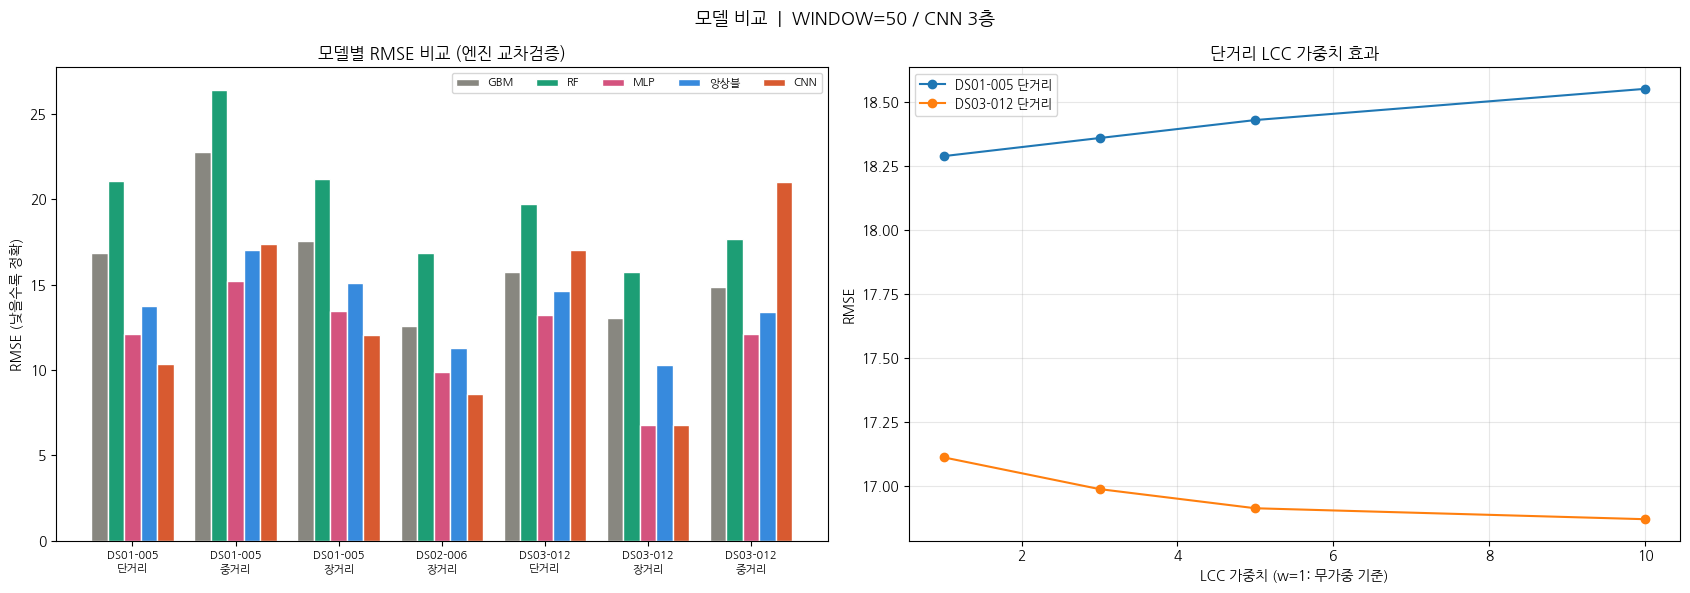

In [24]:
#시각화

labels = list(results.keys())
n = len(labels)
MODELS_V = [('gbm','GBM','#888780'), ('rf','RF','#1D9E75'),
            ('mlp','MLP','#D4537E'), ('ensemble','앙상블','#378ADD'),
            ('cnnlstm','CNN','#D85A30')]

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# 왼쪽: 모델별 그룹 막대 (RMSE 평균)
ax = axes[0]
x = np.arange(n); nb = len(MODELS_V); width = 0.8 / nb
for j, (key, disp, color) in enumerate(MODELS_V):
    if key == 'cnnlstm':
        vals = [results[k]['cnn'][0] if results[k]['cnn'] else 0 for k in labels]
    else:
        vals = [results[k]['cv'][key][0] if results[k]['cv'][key] else 0 for k in labels]
    ax.bar(x + (j - nb/2 + 0.5)*width, vals, width, label=disp, color=color, edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels([l.replace(' / ', '\n') for l in labels], fontsize=8)
ax.set_ylabel('RMSE (낮을수록 정확)')
ax.set_title('모델별 RMSE 비교 (엔진 교차검증)', fontweight='bold')
ax.legend(fontsize=8, ncol=5)

# 오른쪽: 단거리 LCC 가중치 스윕
ax = axes[1]
short = [k for k in labels if results[k]['fc'] == 1 and results[k]['lcc_sweep']]
if short:
    for k in short:
        ws = sorted(results[k]['lcc_sweep'].keys())
        ax.plot(ws, [results[k]['lcc_sweep'][w] for w in ws], marker='o',
                label=k.replace(' / ', ' '))
    ax.set_xlabel('LCC 가중치 (w=1: 무가중 기준)')
    ax.set_ylabel('RMSE')
    ax.set_title('단거리 LCC 가중치 효과', fontweight='bold')
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
else:
    ax.text(0.5, 0.5, '단거리 데이터 없음', ha='center', va='center', transform=ax.transAxes)

plt.suptitle(f'모델 비교  |  WINDOW={WINDOW} / CNN {CNN_LAYERS}층', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/모델비교.png', dpi=150, bbox_inches='tight')
plt.show()

In [25]:
# 결과 요약

print("\n" + "="*78)
print("  모델별 RMSE 평균 요약  (엔진 교차검증)")
print("="*78)
print(f"\n  {'실험':24s} {'엔진':>4}   {'GBM':>6} {'RF':>6} {'MLP':>6} {'앙상블':>6} {'CNN':>6}")
print("  " + "-"*72)

def cell(v):
    return f"{v[0]:6.2f}" if v else "   -  "

def keyf(item):
    cv = item[1]['cv']
    return cv['ensemble'][0] if cv and cv['ensemble'] else 99

for k, v in sorted(results.items(), key=keyf):
    cv = v['cv']
    g, r, m, e = cell(cv['gbm']), cell(cv['rf']), cell(cv['mlp']), cell(cv['ensemble'])
    c = cell(v['cnn'])
    flag = "*" if v['n_engines'] < 3 else " "
    print(f"  {k:24s} {v['n_engines']:>3}{flag}  {g} {r} {m} {e} {c}")
print("="*78)

print("\n  [모델별 전체 평균 RMSE]")
for name, disp in [('gbm','GBM'), ('rf','RF'), ('mlp','MLP'), ('ensemble','앙상블')]:
    vals = [v['cv'][name][0] for v in results.values() if v['cv'] and v['cv'][name]]
    if vals:
        print(f"    {disp:7s} {np.mean(vals):.2f}")
cnn_vals = [v['cnn'][0] for v in results.values() if v['cnn']]
if cnn_vals:
    print(f"    {'CNN':7s} {np.mean(cnn_vals):.2f}")
print("\n  * = 엔진<3 → 폴드 분산 큼(단일 RMSE로 우열 판단 금지).")


  모델별 RMSE 평균 요약  (엔진 교차검증)

  실험                         엔진      GBM     RF    MLP    앙상블    CNN
  ------------------------------------------------------------------------
  DS03-012 / 장거리             2*   13.03  15.76   6.75  10.32   6.75
  DS02-006 / 장거리             6    12.59  16.83   9.89  11.27   8.60
  DS03-012 / 중거리             4    14.88  17.69  12.12  13.41  21.02
  DS01-005 / 단거리             2*   16.88  21.08  12.13  13.76  10.35
  DS03-012 / 단거리             3    15.72  19.75  13.25  14.63  17.03
  DS01-005 / 장거리             2*   17.56  21.17  13.44  15.09  12.06
  DS01-005 / 중거리             2*   22.80  26.41  15.23  17.02  17.36

  [모델별 전체 평균 RMSE]
    GBM     16.21
    RF      19.81
    MLP     11.83
    앙상블     13.64
    CNN     13.31

  * = 엔진<3 → 폴드 분산 큼(단일 RMSE로 우열 판단 금지).
